Specific physical properties for exoplanets!!

In [ ]:
import ads as ads
import pandas as pd
import scipy as scipy
import seaborn as sns
import numpy as np
ads.config.token = "ADD TOKEN HERE"
planetary_lemons = pd.read_csv("exoplanet_views.csv")

In [ ]:
planetary_lemons = pd.read_csv("exoplanet_views.csv")

0       ('Alpha Centauri Ab (?)', 'https://en.wikipedi...
1       ('Beta Pictoris b', 'https://en.wikipedia.org/...
2       ('51 Eridani b', 'https://en.wikipedia.org/wik...
3       ('HR 8799 e', 'https://en.wikipedia.org/wiki/H...
4       ('HR 8799 d', 'https://en.wikipedia.org/wiki/H...
                              ...                        
1345    ('TOI-732 c', 'https://en.wikipedia.org/wiki/L...
1346    ('TOI-270 b', 'https://en.wikipedia.org/wiki/T...
1347    ('TOI-270 d', 'https://en.wikipedia.org/wiki/T...
1348    ('L 168-9 b (Qingluan)', 'https://en.wikipedia...
1349    ('HD 3167 b', 'https://en.wikipedia.org/wiki/H...
Name: 0, Length: 1350, dtype: str


In [ ]:
q = ads.SearchQuery(q = "trappist 1", rows=50, sort = "citation_count desc")
citations = pd.DataFrame(columns=["object", "num_citations", "num_views"])

def get_citations(query):
    '''returns the number of citations from the first 100 papers 
    for a given string "query", requires that the ads python package is installed and configured
      with a valid token'''
    citation_count = 0
    q = ads.SearchQuery(q = query, rows=100, sort = "citation_count desc")
    for paper in q:
        citation_count += paper.citation_count
    return citation_count

def chunked_citation_generator(index = 0, chunk_size = 10, citations = citations, input = planetary_lemons):
    '''populates the 'citations' dataframe with the naem of the object, starting at index 'index'
      with a size of 'chunk_size' we must 'chunk' the number of citations and views for each celestial object in 
      'input' dataframe because of API rate limits number of citations citations and then numbe of views for each 
      celestial object in 'input' dataframe requires that 'citations' has the fields: 'num_citations', 'object', 'num_views' 
      and that 'input' has the fields: '0', and 'view_count' reuires 'len('input') > index and index >= 0 and chunk_size > 0'''
    i = index
    while (i < (index + chunk_size)) and (i < len(input)):
        name = input['0'][i].split("'")[1]
        citations.loc[i, 'num_citations'] = get_citations(name)
        citations.loc[i, 'object'] = name
        citations.loc[i, 'num_views'] = input['view_count'][i]
        i += 1



In [67]:
i = 0
while(i < len(planetary_lemons)):
    chunked_citation_generator(index = i, chunk_size = 10, citations = citations, input = planetary_lemons)
    i += 10
    print(i)

APIResponseError: '<!doctype html>\n<html lang=en>\n<title>429 Too Many Requests</title>\n<h1>Too Many Requests</h1>\n<p>5000 per 86400 second</p>\n'

<Axes: xlabel='num_views', ylabel='num_citations'>

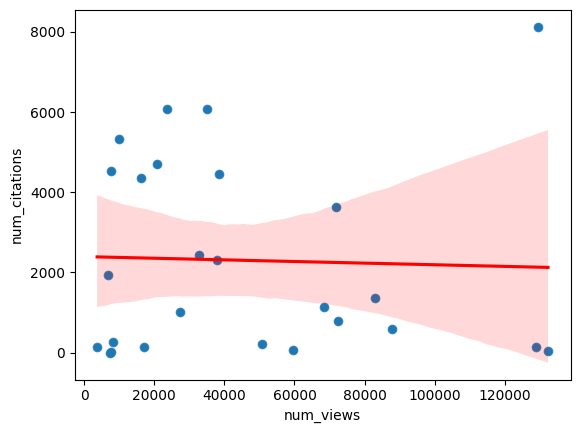

In [ ]:
no_outliar = citations.drop(citations.index[25])
sns.scatterplot(data = no_outliar, x = "num_views", y = "num_citations")
x = np.array(no_outliar["num_views"])
y = np.array(no_outliar["num_citations"])
xval = []
yval = []
for i in range(len(x)):
    xval.append(int(x[i]))
for i in range(len(x)):
    yval.append(int(y[i]))
results = scipy.stats.linregress(xval, yval)
sns.regplot(x = xval, y = yval, line_kws={"color": "red"})


In [66]:
citations.head(50)

,object,num_citations,num_views
0,Alpha Centauri Ab (?),3621,71834.0
1,Beta Pictoris b,8129,129344.0
2,51 Eridani b,2310,37943.0
3,HR 8799 e,4453,38382.0
4,HR 8799 d,4713,20850.0
5,HR 8799 c,6079,23753.0
6,HR 8799 b,6078,34965.0
7,HIP 99770 b,145,17002.0
8,14 Herculis c,4349,16364.0
9,HR 2562 B,257,8202.0
